In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
import pandas as pd

df = pd.read_csv(
    "/content/Sample - Superstore.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [11]:
# 1. Dataset mein kitni rows aur columns hain?
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Har column ka data type
print("\nData Types:")
print(df.dtypes)

# 4. Missing values check
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Duplicate rows check
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Numerical columns ka statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data Types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name   

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [12]:
business_questions = [
    "Which category generates the highest sales?",
    "Which category generates the highest profit?",
    "Which region has the highest sales?",
    "Which products are most profitable?",
    "Which products have losses?",
    "How do sales change over time?",
    "Which segment generates the highest sales?",
    "How do discounts affect profit?",
    "Which ship mode is most commonly used?",
    "Which sub-categories have the highest sales?"
]

for i, question in enumerate(business_questions, 1):
    print(f"{i}. {question}")

1. Which category generates the highest sales?
2. Which category generates the highest profit?
3. Which region has the highest sales?
4. Which products are most profitable?
5. Which products have losses?
6. How do sales change over time?
7. Which segment generates the highest sales?
8. How do discounts affect profit?
9. Which ship mode is most commonly used?
10. Which sub-categories have the highest sales?


In [13]:
print(df.dtypes)

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [14]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [15]:
print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nInvalid dates:")
print(df[["Order Date", "Ship Date"]].isnull().sum())

print("\nNegative sales:", (df["Sales"] < 0).sum())
print("Negative quantity:", (df["Quantity"] < 0).sum())
print("Negative profit:", (df["Profit"] < 0).sum())

Rows and columns: (9994, 21)
Missing values: 0
Duplicate rows: 0

Invalid dates:
Order Date    0
Ship Date     0
dtype: int64

Negative sales: 0
Negative quantity: 0
Negative profit: 1871


In [16]:
display(df.describe().round(2))

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.00,9994,9994,9994.00,9994.00,9994.00,9994.00,9994.00
mean,4997.50,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.38,229.86,3.79,0.16,28.66
min,1.00,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.00,0.44,1.00,0.00,-6599.98
25%,2499.25,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.00,17.28,2.00,0.00,1.73
50%,4997.50,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.50,54.49,3.00,0.20,8.67
75%,7495.75,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.00,209.94,5.00,0.20,29.36
max,9994.00,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.00,22638.48,14.00,0.80,8399.98
std,2885.16,NaN,NaN,32063.69,623.25,2.23,0.21,234.26


In [17]:
df_eda = df.copy()

df_eda["Order Year"] = df_eda["Order Date"].dt.year
df_eda["Order Month"] = df_eda["Order Date"].dt.month

df_eda["Order Month Name"] = (
    df_eda["Order Date"].dt.strftime("%b")
)

df_eda["Order Month Start"] = (
    df_eda["Order Date"].dt.to_period("M").dt.to_timestamp()
)

print(df_eda[
    ["Order Date", "Order Year", "Order Month",
     "Order Month Name", "Order Month Start"]
].head())

  Order Date  Order Year  Order Month Order Month Name Order Month Start
0 2016-11-08        2016           11              Nov        2016-11-01
1 2016-11-08        2016           11              Nov        2016-11-01
2 2016-06-12        2016            6              Jun        2016-06-01
3 2015-10-11        2015           10              Oct        2015-10-01
4 2015-10-11        2015           10              Oct        2015-10-01


In [18]:
total_sales = df_eda["Sales"].sum()
total_profit = df_eda["Profit"].sum()
total_orders = df_eda["Order ID"].nunique()
total_customers = df_eda["Customer ID"].nunique()
total_products = df_eda["Product ID"].nunique()
total_quantity = df_eda["Quantity"].sum()
average_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")
print(f"Total Quantity: {total_quantity:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Products: 1,862
Total Quantity: 37,873
Average Order Value: $458.61


In [19]:
category_sales = (
    df_eda.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales)

,Sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


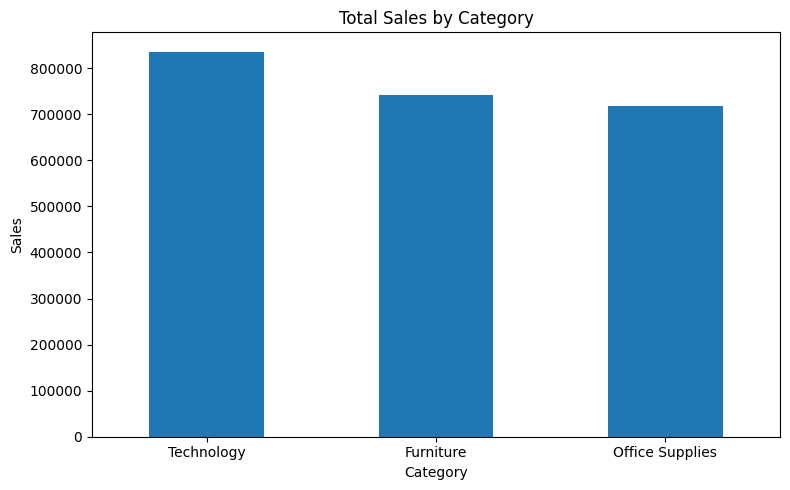

In [20]:
category_sales.plot(
    kind="bar",
    title="Total Sales by Category",
    xlabel="Category",
    ylabel="Sales",
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Profit
Category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


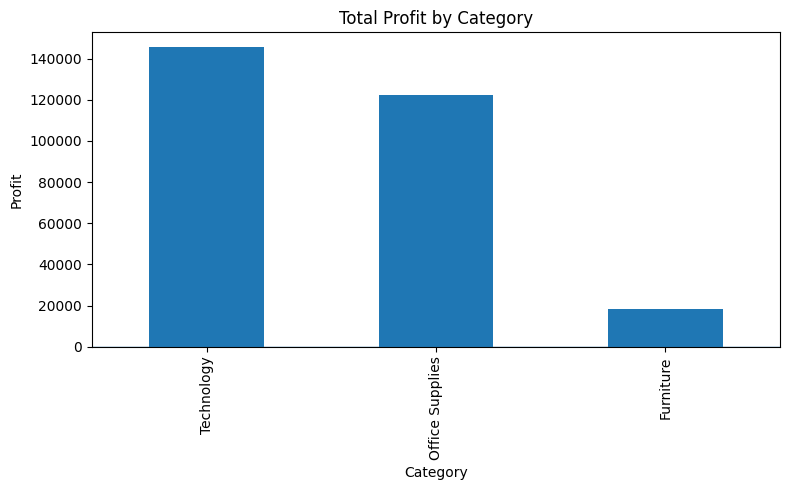

In [21]:
category_profit = (
    df_eda.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

display(category_profit)

category_profit.plot(
    kind="bar",
    title="Total Profit by Category",
    xlabel="Category",
    ylabel="Profit",
    figsize=(8, 5)
)

plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

,Sales
Region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050


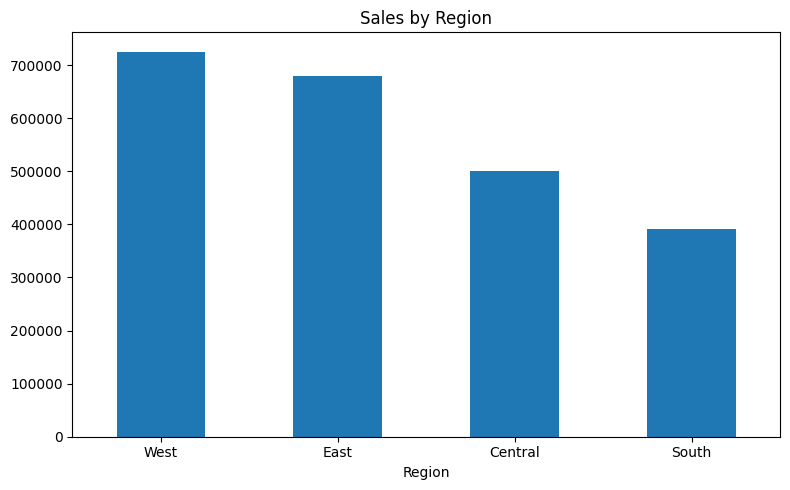

In [23]:
region_sales = (
    df_eda.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(region_sales)

region_sales.plot(
    kind="bar",
    title="Sales by Region",
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
segment_analysis = df_eda.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(segment_analysis)

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Segment,,,,
Consumer,1161401.34,134119.21,2586,19521
Corporate,706146.37,91979.13,1514,11608
Home Office,429653.15,60298.68,909,6744


,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


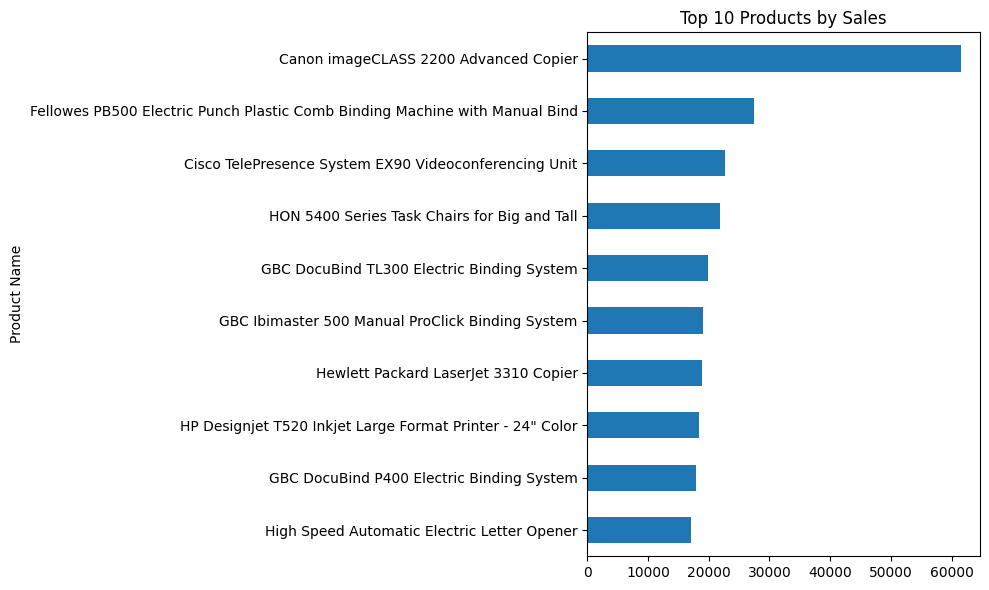

In [25]:
top_products = (
    df_eda.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

top_products.sort_values().plot(
    kind="barh",
    title="Top 10 Products by Sales",
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [26]:
top_profit_products = (
    df_eda.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_profit_products)

,Profit
Product Name,
Canon imageCLASS 2200 Advanced Copier,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,7753.0390
Hewlett Packard LaserJet 3310 Copier,6983.8836
Canon PC1060 Personal Laser Copier,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",4094.9766
Ativa V4110MDD Micro-Cut Shredder,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,3696.2820
Ibico EPK-21 Electric Binding System,3345.2823


In [27]:
loss_products = (
    df_eda.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
)

display(loss_products.head(10))

,Profit
Product Name,
Cubify CubeX 3D Printer Double Head Print,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.1156
Bush Advantage Collection Racetrack Conference Table,-1934.3976
GBC DocuBind P400 Electric Binding System,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,-1299.1836
Balt Solid Wood Round Tables,-1201.0581


In [28]:
subcategory_analysis = (
    df_eda.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(subcategory_analysis)

,Total_Sales,Total_Profit
Sub-Category,,
Phones,330007.0540,44515.7306
Chairs,328449.1030,26590.1663
Storage,223843.6080,21278.8264
Tables,206965.5320,-17725.4811
Binders,203412.7330,30221.7633
Machines,189238.6310,3384.7569
Accessories,167380.3180,41936.6357
Copiers,149528.0300,55617.8249
Bookcases,114879.9963,-3472.5560


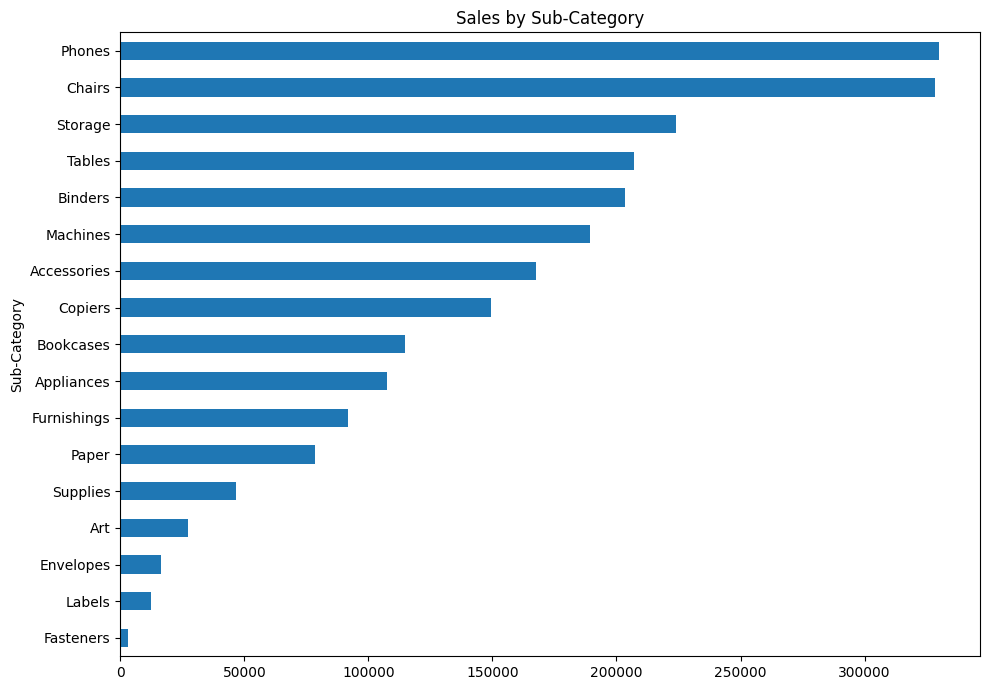

In [29]:
subcategory_analysis["Total_Sales"].sort_values().plot(
    kind="barh",
    title="Sales by Sub-Category",
    figsize=(10, 7)
)

plt.tight_layout()
plt.show()

,Sales
Order Month Start,
2014-01-01,14236.8950
2014-02-01,4519.8920
2014-03-01,55691.0090
2014-04-01,28295.3450
2014-05-01,23648.2870
2014-06-01,34595.1276
2014-07-01,33946.3930
2014-08-01,27909.4685
2014-09-01,81777.3508


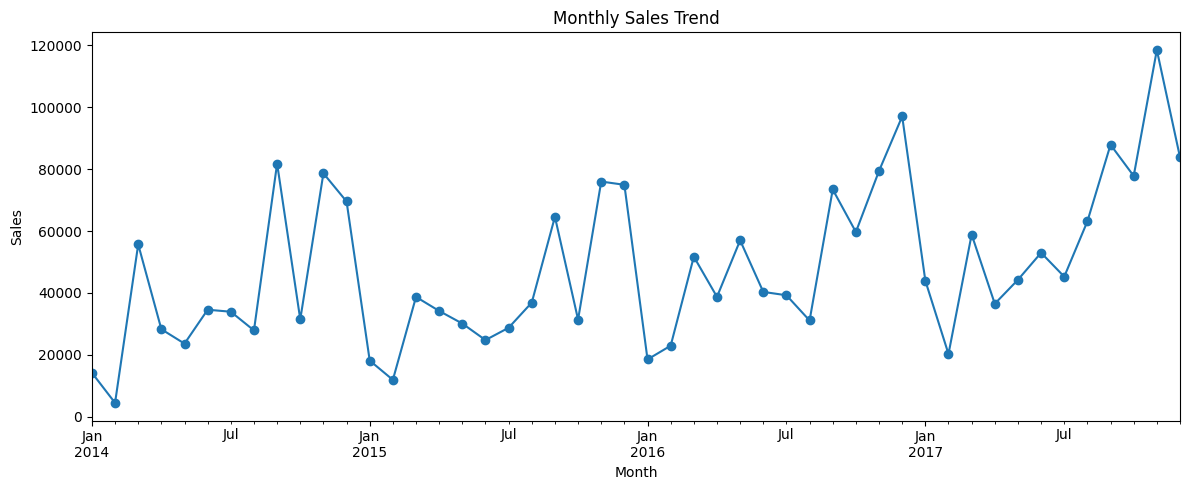

In [30]:
monthly_sales = (
    df_eda.groupby("Order Month Start")["Sales"]
    .sum()
    .sort_index()
)

display(monthly_sales)

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend",
    xlabel="Month",
    ylabel="Sales",
    figsize=(12, 5)
)

plt.tight_layout()
plt.show()

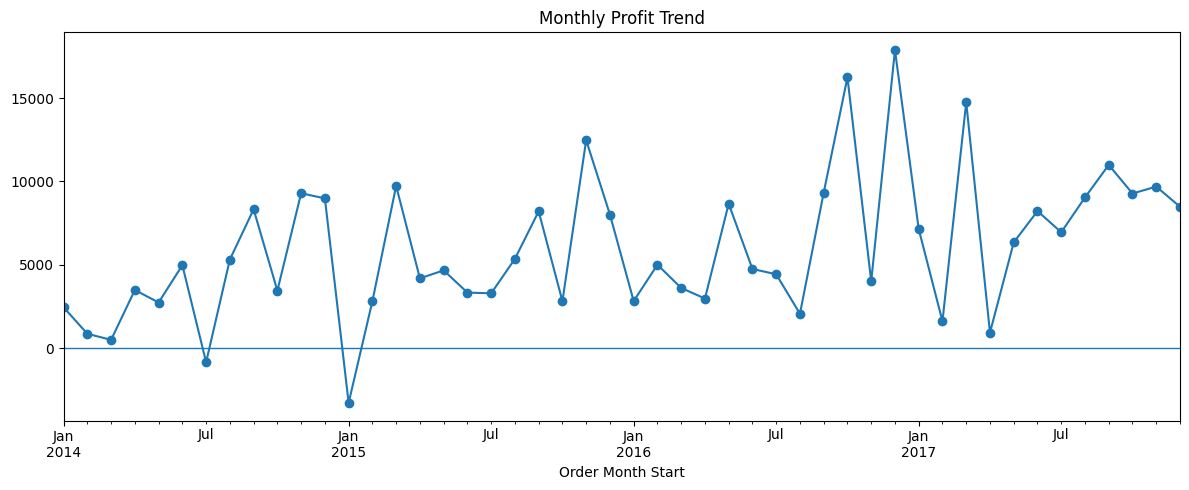

In [31]:
monthly_profit = (
    df_eda.groupby("Order Month Start")["Profit"]
    .sum()
    .sort_index()
)

monthly_profit.plot(
    kind="line",
    marker="o",
    title="Monthly Profit Trend",
    figsize=(12, 5)
)

plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

In [32]:
discount_analysis = (
    df_eda.groupby("Discount")
    .agg(
        Average_Profit=("Profit", "mean"),
        Total_Profit=("Profit", "sum"),
        Order_Lines=("Order ID", "size")
    )
    .round(2)
)

display(discount_analysis)

,Average_Profit,Total_Profit,Order_Lines
Discount,,,
0.00,66.90,320987.60,4798
0.10,96.06,9029.18,94
0.15,27.29,1418.99,52
0.20,24.70,90337.31,3657
0.30,-45.68,-10369.28,227
0.32,-88.56,-2391.14,27
0.40,-111.93,-23057.05,206
0.45,-226.65,-2493.11,11
0.50,-310.70,-20506.43,66


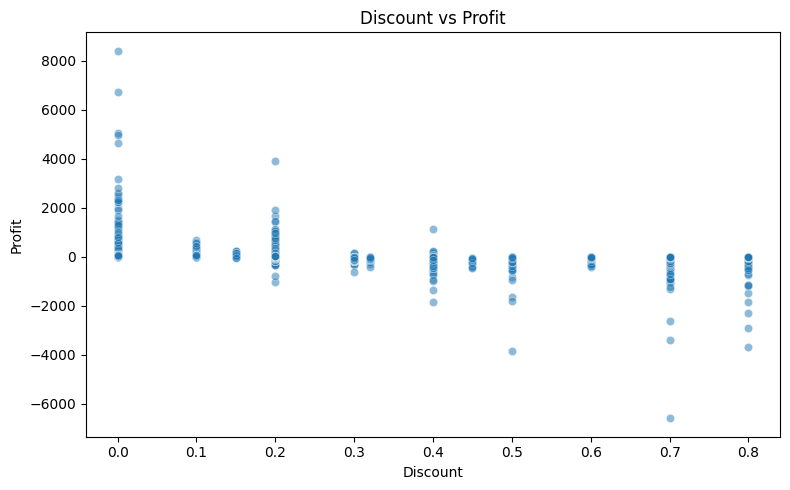

In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_eda,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.title("Discount vs Profit")
plt.tight_layout()
plt.show()

In [34]:
ship_analysis = (
    df_eda.groupby("Ship Mode")
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Orders", ascending=False)
)

display(ship_analysis)

,Total_Orders,Total_Sales,Total_Profit
Ship Mode,,,
Standard Class,2994,1.358216e+06,164088.7875
Second Class,964,4.591936e+05,57446.6354
First Class,787,3.514284e+05,48969.8399
Same Day,264,1.283631e+05,15891.7589


,Sales,Quantity,Discount,Profit
Sales,1.00,0.20,-0.03,0.48
Quantity,0.20,1.00,0.01,0.07
Discount,-0.03,0.01,1.00,-0.22
Profit,0.48,0.07,-0.22,1.00


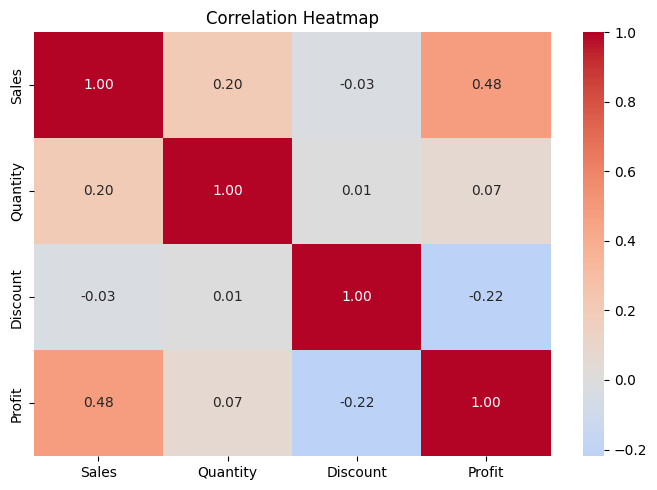

In [36]:
numeric_cols = [
    "Sales", "Quantity", "Discount", "Profit"
]

correlation = df_eda[numeric_cols].corr()

display(correlation.round(2))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

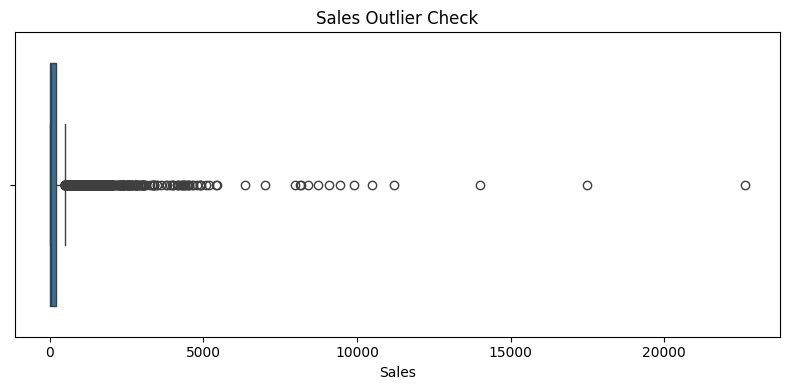

In [37]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df_eda, x="Sales")

plt.title("Sales Outlier Check")
plt.tight_layout()
plt.show()

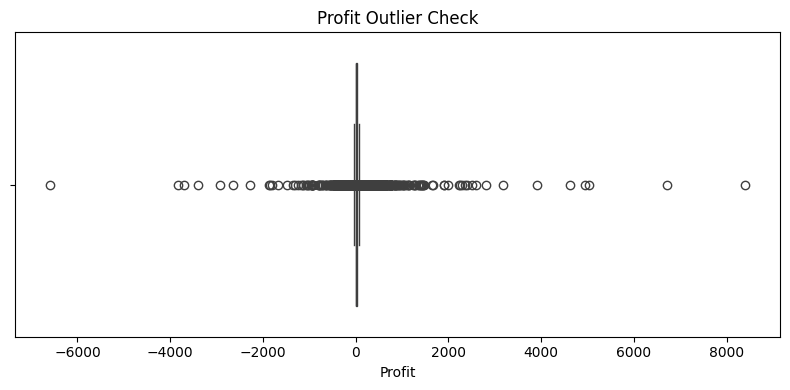

In [38]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df_eda, x="Profit")

plt.title("Profit Outlier Check")
plt.tight_layout()
plt.show()

In [39]:
print("Missing values per column:")
print(df_eda.isnull().sum())

print("\nExact duplicate rows:", df_eda.duplicated().sum())

Missing values per column:
Row ID               0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
Customer ID          0
Customer Name        0
Segment              0
Country              0
City                 0
State                0
Postal Code          0
Region               0
Product ID           0
Category             0
Sub-Category         0
Product Name         0
Sales                0
Quantity             0
Discount             0
Profit               0
Order Year           0
Order Month          0
Order Month Name     0
Order Month Start    0
dtype: int64

Exact duplicate rows: 0


In [40]:
findings = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Total Quantity",
        "Average Order Value"
    ],
    "Value": [
        round(total_sales, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        total_products,
        total_quantity,
        round(average_order_value, 2)
    ]
})

display(findings)

,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Total Orders,5009.00
3,Total Customers,793.00
4,Total Products,1862.00
5,Total Quantity,37873.00
6,Average Order Value,458.61


In [41]:
findings.to_csv(
    "superstore_eda_summary.csv",
    index=False
)

category_analysis = df_eda.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

category_analysis.to_csv(
    "superstore_category_analysis.csv",
    index=False
)

print("Summary and category analysis files saved!")

Summary and category analysis files saved!


In [42]:
from google.colab import files

files.download("superstore_eda_summary.csv")
files.download("superstore_category_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:

# Create EDA Report

from datetime import datetime

report = []

report.append("SUPERSTORE EXPLORATORY DATA ANALYSIS REPORT")
report.append("=" * 50)
report.append("")

report.append("1. PROJECT OVERVIEW")
report.append(
    "This project analyzes the Sample Superstore dataset "
    "using Python, Pandas, Matplotlib and Seaborn."
)
report.append("")

report.append("2. DATASET INFORMATION")
report.append(f"Total rows: {df_eda.shape[0]}")
report.append(f"Total columns: {df_eda.shape[1]}")
report.append(f"Missing values: {df_eda.isnull().sum().sum()}")
report.append(f"Duplicate rows: {df_eda.duplicated().sum()}")
report.append("")

report.append("3. KEY PERFORMANCE INDICATORS")
report.append(f"Total Sales: ${total_sales:,.2f}")
report.append(f"Total Profit: ${total_profit:,.2f}")
report.append(f"Total Orders: {total_orders:,}")
report.append(f"Total Customers: {total_customers:,}")
report.append(f"Total Products: {total_products:,}")
report.append(f"Total Quantity: {total_quantity:,}")
report.append(
    f"Average Order Value: ${average_order_value:,.2f}"
)
report.append("")

report.append("4. SALES BY CATEGORY")
report.append(category_sales.to_string())
report.append("")

report.append("5. PROFIT BY CATEGORY")
report.append(category_profit.to_string())
report.append("")

report.append("6. SALES BY REGION")
report.append(region_sales.to_string())
report.append("")

report.append("7. TOP 10 PRODUCTS BY SALES")
report.append(top_products.to_string())
report.append("")

report.append("8. TOP 10 LOSS-MAKING PRODUCTS")
report.append(loss_products.head(10).to_string())
report.append("")

report.append("9. MONTHLY SALES")
report.append(monthly_sales.to_string())
report.append("")

report.append("10. CONCLUSION")
report.append(
    "The analysis examines sales, profitability, customer "
    "segments, products, regions and monthly trends. "
    "Business recommendations should be based on the "
    "observed results and visualizations."
)

report_text = "\n".join(report)

with open("Superstore_EDA_Report.txt", "w", encoding="utf-8") as file:
    file.write(report_text)

print("EDA report created successfully!")
print(report_text)


EDA report created successfully!
SUPERSTORE EXPLORATORY DATA ANALYSIS REPORT

1. PROJECT OVERVIEW
This project analyzes the Sample Superstore dataset using Python, Pandas, Matplotlib and Seaborn.

2. DATASET INFORMATION
Total rows: 9994
Total columns: 25
Missing values: 0
Duplicate rows: 0

3. KEY PERFORMANCE INDICATORS
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Products: 1,862
Total Quantity: 37,873
Average Order Value: $458.61

4. SALES BY CATEGORY
Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320

5. PROFIT BY CATEGORY
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728

6. SALES BY REGION
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050

7. TOP 10 PRODUCTS BY SALES
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB

In [44]:
from google.colab import files
files.download("Superstore_EDA_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>